##  01. Introduction

# Upcoming Movie Predictions

## Objective
Use the final saved models to predict worldwide box office revenue
and blockbuster probabilities for the selected upcoming movies.

## Workflow
1. Locate saved models and prediction data.
2. Load models and their saved configuration.
3. Validate prediction features against model requirements.
4. Generate revenue predictions and blockbuster probabilities.
5. Review limitations and export results.

## Rules
- Use pre-release information only.
- Preserve the training feature definitions and preprocessing.
- Use the classification threshold selected during validation.
- Do not retrain models or adjust thresholds in this notebook.

Audit update 30 September 2026: indicator status ordering corrected; consolidation uses the current run; cohort and budget provenance retained; budget status distinguishes missing values, reported minima and provisional midpoints. Model training, parameters and prediction inputs are unchanged. Outputs are cleared pending a full run in the original scikit-learn 1.6.1 environment.

## 02. Import libraries

In [1]:
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 03. Project Folders

In [2]:
# Find the project root from the notebook's working directory.
current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        folder
        for folder in [current_dir, *current_dir.parents]
        if (folder / "Data" / "Models" / "Final").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate Data/Models/Final. "
        "Open this notebook inside your Movie Analysis Predictor project."
    )

MODEL_DIR = PROJECT_ROOT / "Data" / "Models" / "Final"
EVALUATION_DIR = PROJECT_ROOT / "Data" / "Results" / "Final_Evaluation"
FEATURE_PATH = (
    PROJECT_ROOT / "Data" / "Features" / "prediction_target_features.csv"
)

print(f"Project root: {PROJECT_ROOT}")

file_records = []

for category, folder in [
    ("Saved model / configuration", MODEL_DIR),
    ("Final evaluation", EVALUATION_DIR),
]:
    if folder.is_dir():
        for file in sorted(folder.rglob("*")):
            if file.is_file():
                file_records.append({
                    "category": category,
                    "file": str(file.relative_to(PROJECT_ROOT)),
                    "size_kb": round(file.stat().st_size / 1024, 2),
                })

display(pd.DataFrame(
    file_records,
    columns=["category", "file", "size_kb"],
))

if not FEATURE_PATH.is_file():
    raise FileNotFoundError(
        f"Prediction feature dataset not found: {FEATURE_PATH}"
    )

print(f"\nPrediction features: {FEATURE_PATH.relative_to(PROJECT_ROOT)}")

Project root: C:\Users\bongo\OneDrive\Desktop\GitHub\Movie Analysis Predictor


,category,file,size_kb
0,Saved model / configuration,Data\Models\Final\blockbuster_classifier.joblib,21139.99
1,Saved model / configuration,Data\Models\Final\model_manifest.json,1.59
2,Saved model / configuration,Data\Models\Final\preprocessor.joblib,5.54
3,Saved model / configuration,Data\Models\Final\revenue_regressor.joblib,899.65
4,Final evaluation,Data\Results\Final_Evaluation\classification_confusion_matrix.csv,0.10
5,Final evaluation,Data\Results\Final_Evaluation\classification_test_metrics.json,0.17
6,Final evaluation,Data\Results\Final_Evaluation\regression_test_metrics.json,0.18
7,Final evaluation,Data\Results\Final_Evaluation\test_predictions.csv,22.28



Prediction features: Data\Features\prediction_target_features.csv


## 04. Loading and inspecting prediction features

In [3]:
prediction_features = pd.read_csv(FEATURE_PATH)

if prediction_features.empty:
    raise ValueError("The prediction feature dataset contains no movies.")

print(f"Movies: {len(prediction_features):,}")
print(f"Columns: {prediction_features.shape[1]:,}")

display(prediction_features.head(10))

feature_audit = pd.DataFrame({
    "column": prediction_features.columns,
    "dtype": prediction_features.dtypes.astype(str).to_numpy(),
    "missing_count": prediction_features.isna().sum().to_numpy(),
    "missing_percent": (
        prediction_features.isna().mean().mul(100).round(2).to_numpy()
    ),
})

display(feature_audit)

print(
    "\nInspection complete. Missing values have been preserved "
    "for validation against the saved preprocessing."
)

Movies: 19
Columns: 18


,title,cohort,release_date,log_budget,release_year,release_month,release_quarter,holiday_release,director_prior_films,director_prior_avg_gross,star_prior_films,star_prior_avg_gross,company_prior_films,company_prior_avg_gross,primary_genre,release_season,worldwide_box_office,log_worldwide_box_office
0,Spider-Man: Brand New Day,released_backtest,2026-07-31,19.231611,2026,7,3,0,2,1.186685e+07,3,7.180152e+08,332,1.295450e+08,Action,summer,2.402937e+09,21.599958
1,Michael,released_backtest,2026-04-24,18.951309,2026,4,2,0,12,1.148616e+08,0,NaN,4,8.660476e+07,Biography,spring,1.021427e+09,20.744466
2,The Odyssey,released_backtest,2026-07-17,19.336971,2026,7,3,0,11,4.685044e+08,25,1.616126e+08,1,5.270163e+08,Adventure,summer,1.627387e+09,21.210241
3,Scary Movie,released_backtest,2026-06-05,17.216708,2026,6,2,0,3,3.591527e+07,8,1.452784e+08,74,5.097942e+07,Comedy,summer,2.312778e+08,19.259130
4,Mortal Kombat II,released_backtest,2026-05-08,18.197537,2026,5,2,0,0,NaN,4,3.527871e+07,174,1.142747e+08,Action,summer,1.294701e+08,18.678961
5,The Super Mario Galaxy Movie,released_backtest,2026-04-03,18.515991,2026,4,2,0,0,NaN,6,8.797427e+08,2,1.097122e+09,Animation,spring,1.012793e+09,20.735978
6,The Devil Wears Prada 2,released_backtest,2026-05-01,18.420681,2026,5,2,0,7,1.156514e+08,25,9.141235e+07,0,NaN,Comedy,summer,6.928175e+08,20.356277
7,Toy Story 5,released_backtest,2026-06-19,18.980297,2026,6,2,0,4,6.935936e+08,41,2.427420e+08,12,6.571954e+08,Animation,summer,1.137320e+09,20.851940
8,GOAT,released_backtest,2026-02-13,18.197537,2026,2,1,0,0,NaN,0,NaN,4,2.319894e+08,Animation,winter,1.953569e+08,19.090339
9,Backrooms,released_backtest,2026-05-29,16.118096,2026,5,2,0,0,NaN,6,4.158317e+07,8,2.547500e+07,Horror,summer,3.931673e+08,19.789746


,column,dtype,missing_count,missing_percent
0,title,object,0,0.00
1,cohort,object,0,0.00
2,release_date,object,0,0.00
3,log_budget,float64,9,47.37
4,release_year,int64,0,0.00
5,release_month,int64,0,0.00
6,release_quarter,int64,0,0.00
7,holiday_release,int64,0,0.00
8,director_prior_films,int64,0,0.00
9,director_prior_avg_gross,float64,6,31.58



Inspection complete. Missing values have been preserved for validation against the saved preprocessing.


## 05. LOAD SAVED MODEL FILES

In [4]:
from sklearn.base import is_classifier, is_regressor

model_files = sorted(
    path
    for path in MODEL_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".joblib", ".pkl", ".pickle"}
)

if not model_files:
    raise FileNotFoundError(f"No saved model files found in {MODEL_DIR}")

loaded_objects = {}
model_inventory = []

for path in model_files:
    # These must be your own trusted model files.
    saved_object = joblib.load(path)
    relative_name = str(path.relative_to(MODEL_DIR))
    loaded_objects[relative_name] = saved_object

    # Support models saved directly or inside a dictionary.
    candidates = (
        saved_object.items()
        if isinstance(saved_object, dict)
        else [("model", saved_object)]
    )

    for object_name, candidate in candidates:
        if not callable(getattr(candidate, "predict", None)):
            continue

        model_kind = (
            "classification" if is_classifier(candidate)
            else "regression" if is_regressor(candidate)
            else "unknown"
        )

        model_inventory.append({
            "file": relative_name,
            "object_name": object_name,
            "model_kind": model_kind,
            "python_type": type(candidate).__name__,
        })

model_inventory_df = pd.DataFrame(model_inventory)

if model_inventory_df.empty:
    raise ValueError("Files loaded, but no prediction models were identified.")

display(model_inventory_df)

,file,object_name,model_kind,python_type
0,blockbuster_classifier.joblib,model,classification,RandomForestClassifier
1,revenue_regressor.joblib,model,regression,HistGradientBoostingRegressor


## 06. SELECT THE FINAL REGRESSION AND CLASSIFICATION MODELS

In [5]:
def select_saved_model(model_kind):
    matches = model_inventory_df.loc[
        model_inventory_df["model_kind"].eq(model_kind)
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one {model_kind} model, found {len(matches)}. "
            "Review the Cell 5 inventory before continuing."
        )

    selected = matches.iloc[0]
    saved_object = loaded_objects[selected["file"]]

    model = (
        saved_object[selected["object_name"]]
        if isinstance(saved_object, dict)
        else saved_object
    )

    print(f"{model_kind.capitalize()}: {selected['file']}")
    return model


regression_model = select_saved_model("regression")
classification_model = select_saved_model("classification")

print("\nBoth final models loaded successfully.")

Regression: revenue_regressor.joblib
Classification: blockbuster_classifier.joblib

Both final models loaded successfully.


In [6]:
# Inspect saved preprocessing without changing or retraining anything.
def inspect_saved_object(obj, label, depth=0):
    print(f"\n{label}: {type(obj).__name__}")

    for attribute in ("feature_names_in_", "get_feature_names_out"):
        try:
            value = getattr(obj, attribute, None)
            if callable(value):
                value = value()
            if value is not None:
                print(f"{attribute}: {list(value)}")
        except Exception as error:
            print(f"{attribute}: {error}")

    if depth >= 3:
        return

    if isinstance(obj, dict):
        print("Dictionary keys:", list(obj))
        for key, value in obj.items():
            inspect_saved_object(value, f"{label} → {key}", depth + 1)

    elif hasattr(obj, "steps"):
        for name, step in obj.steps:
            inspect_saved_object(step, f"{label} → {name}", depth + 1)

    elif hasattr(obj, "transformers_"):
        for name, transformer, columns in obj.transformers_:
            print(f"\nTransformer: {name}")
            print("Input columns:", columns)
            inspect_saved_object(
                transformer, f"{label} → {name}", depth + 1
            )


for filename, saved_object in loaded_objects.items():
    inspect_saved_object(saved_object, filename)

print("\nPreprocessor files in Data:")
for path in sorted((PROJECT_ROOT / "Data").rglob("*preprocessor*")):
    if path.is_file():
        print(path.relative_to(PROJECT_ROOT))


blockbuster_classifier.joblib: RandomForestClassifier
feature_names_in_: ['log_budget', 'release_year', 'release_month', 'holiday_release', 'director_prior_films', 'director_prior_avg_gross', 'star_prior_films', 'star_prior_avg_gross', 'company_prior_films', 'company_prior_avg_gross', 'director_has_prior_history', 'star_has_prior_history', 'company_has_prior_history', 'budget_missing', 'primary_genre_Action', 'primary_genre_Adventure', 'primary_genre_Animation', 'primary_genre_Biography', 'primary_genre_Comedy', 'primary_genre_Crime', 'primary_genre_Drama', 'primary_genre_Family', 'primary_genre_Fantasy', 'primary_genre_Horror', 'primary_genre_Music', 'primary_genre_Mystery', 'primary_genre_Romance', 'primary_genre_Sci-Fi', 'primary_genre_Thriller', 'primary_genre_Western', 'release_season_Unknown', 'release_season_fall', 'release_season_holiday', 'release_season_spring', 'release_season_summer', 'release_season_winter']

preprocessor.joblib: ColumnTransformer
feature_names_in_: ['log

## 07. VALIDATE AND ORDER THE PREDICTION FEATURES

In [7]:
preprocessor = loaded_objects["preprocessor.joblib"]
prediction_inputs = prediction_features.copy()

if prediction_inputs.columns.duplicated().any():
    raise ValueError("Prediction features contain duplicate column names.")

# Recreate indicators before imputation.
# Verify these four definitions against the training notebook.
for entity in ["director", "star", "company"]:
    source = f"{entity}_prior_films"
    indicator = f"{entity}_has_prior_history"

    if indicator not in prediction_inputs.columns:
        counts = pd.to_numeric(
            prediction_inputs[source], errors="raise"
        )
        prediction_inputs[indicator] = counts.gt(0).astype(int)

if "budget_missing" not in prediction_inputs.columns:
    prediction_inputs["budget_missing"] = (
        prediction_inputs["log_budget"].isna().astype(int)
    )

# Select the raw inputs expected by the fitted preprocessor.
raw_columns = list(preprocessor.feature_names_in_)

missing_columns = [
    column for column in raw_columns
    if column not in prediction_inputs.columns
]

if missing_columns:
    raise ValueError(
        f"Missing preprocessor input columns: {missing_columns}"
    )

prediction_inputs = prediction_inputs.loc[:, raw_columns].copy()

# Validate numeric inputs without filling missing values ourselves.
numeric_columns = list(
    preprocessor.named_transformers_["numeric"].feature_names_in_
)

for column in numeric_columns:
    prediction_inputs[column] = pd.to_numeric(
        prediction_inputs[column], errors="raise"
    )

if np.isinf(
    prediction_inputs[numeric_columns].to_numpy(dtype=float)
).any():
    raise ValueError("Numeric prediction inputs contain infinite values.")

# Apply the already-fitted training transformations.
# Do not use fit() or fit_transform() here.
transformed = preprocessor.transform(prediction_inputs)

if hasattr(transformed, "toarray"):
    transformed = transformed.toarray()

# Remove ColumnTransformer prefixes to match the saved model names.
processed_columns = [
    name.split("__", 1)[-1]
    for name in preprocessor.get_feature_names_out()
]

if len(processed_columns) != len(set(processed_columns)):
    raise ValueError("Processed feature names are not unique.")

processed_prediction_features = pd.DataFrame(
    np.asarray(transformed),
    columns=processed_columns,
    index=prediction_inputs.index,
)

if not np.isfinite(
    processed_prediction_features.to_numpy(dtype=float)
).all():
    raise ValueError("Preprocessing produced missing or infinite values.")


def prepare_prediction_inputs(model, data, model_label):
    expected = getattr(model, "feature_names_in_", None)

    if expected is None:
        raise ValueError(
            f"{model_label} has no saved input feature names."
        )

    expected = list(expected)
    missing = [column for column in expected if column not in data.columns]
    extra = [column for column in data.columns if column not in expected]

    if missing or extra:
        raise ValueError(
            f"{model_label} feature mismatch.\n"
            f"Missing: {missing}\n"
            f"Unexpected: {extra}"
        )

    model_inputs = data.loc[:, expected].copy()

    print(
        f"{model_label}: {len(model_inputs):,} movies, "
        f"{model_inputs.shape[1]} processed features — column checks passed."
    )

    return model_inputs


X_prediction_regression = prepare_prediction_inputs(
    regression_model,
    processed_prediction_features,
    "Revenue model",
)

X_prediction_classification = prepare_prediction_inputs(
    classification_model,
    processed_prediction_features,
    "Blockbuster model",
)

display(X_prediction_regression.head())

print(
    "Saved preprocessing applied successfully. "
    "Verify the four indicator definitions against training "
    "before generating predictions."
)

Revenue model: 19 movies, 36 processed features — column checks passed.
Blockbuster model: 19 movies, 36 processed features — column checks passed.


,log_budget,release_year,release_month,holiday_release,director_prior_films,director_prior_avg_gross,star_prior_films,star_prior_avg_gross,company_prior_films,company_prior_avg_gross,director_has_prior_history,star_has_prior_history,company_has_prior_history,budget_missing,primary_genre_Action,primary_genre_Adventure,primary_genre_Animation,primary_genre_Biography,primary_genre_Comedy,primary_genre_Crime,primary_genre_Drama,primary_genre_Family,primary_genre_Fantasy,primary_genre_Horror,primary_genre_Music,primary_genre_Mystery,primary_genre_Romance,primary_genre_Sci-Fi,primary_genre_Thriller,primary_genre_Western,release_season_Unknown,release_season_fall,release_season_holiday,release_season_spring,release_season_summer,release_season_winter
0,2.275484,2.767132,0.116425,-0.439626,-0.114727,-0.491280,-0.158578,7.808709,3.971323,1.300721,0.789915,0.772739,0.700278,-0.605536,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,2.018112,2.767132,-0.757155,-0.439626,2.688487,0.837876,-0.673296,-0.227576,-0.517569,0.555250,0.789915,-1.294098,0.700278,-0.605536,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2.372226,2.767132,0.116425,-0.439626,2.408166,5.401669,3.616016,1.215528,-0.558626,8.201086,0.789915,0.772739,0.700278,-0.605536,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.425407,2.767132,-0.174768,-0.439626,0.165595,-0.180933,0.699284,1.021974,0.440426,-0.063229,0.789915,0.772739,0.700278,-0.605536,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1.326001,2.767132,-0.465962,-0.439626,-0.675369,-0.271736,0.012994,-0.281485,1.808991,1.035619,-1.265960,0.772739,0.700278,-0.605536,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Saved preprocessing applied successfully. Verify the four indicator definitions against training before generating predictions.


## 08. INSPECT SAVED PREDICTION CONFIGURATION

In [8]:
configuration_files = sorted(MODEL_DIR.rglob("*.json"))

if not configuration_files:
    print("No JSON configuration files found in:", MODEL_DIR)
else:
    for path in configuration_files:
        print(f"\n--- {path.relative_to(MODEL_DIR)} ---")

        with path.open("r", encoding="utf-8") as file:
            configuration = json.load(file)

        print(json.dumps(configuration, indent=2, ensure_ascii=False))


--- model_manifest.json ---
{
  "regression_model": "revenue_regressor.joblib",
  "classification_model": "blockbuster_classifier.joblib",
  "preprocessor": "preprocessor.joblib",
  "classification_threshold": 0.57,
  "regression_target": "log_worldwide_box_office",
  "classification_target": "blockbuster",
  "regression_inverse_transform": "np.expm1",
  "model_training_split": "train",
  "model_selection_split": "validation",
  "final_evaluation_split": "test",
  "processed_feature_columns": [
    "log_budget",
    "release_year",
    "release_month",
    "holiday_release",
    "director_prior_films",
    "director_prior_avg_gross",
    "star_prior_films",
    "star_prior_avg_gross",
    "company_prior_films",
    "company_prior_avg_gross",
    "director_has_prior_history",
    "star_has_prior_history",
    "company_has_prior_history",
    "budget_missing",
    "primary_genre_Action",
    "primary_genre_Adventure",
    "primary_genre_Animation",
    "primary_genre_Biography",
    "pr

## 09. VALIDATE SAVED CONFIGURATION

In [9]:
with (MODEL_DIR / "model_manifest.json").open(
    "r", encoding="utf-8"
) as file:
    manifest = json.load(file)

THRESHOLD = float(manifest["classification_threshold"])

if not 0 <= THRESHOLD <= 1:
    raise ValueError("Classification threshold must be between 0 and 1.")

if (
    manifest["regression_target"] != "log_worldwide_box_office"
    or manifest["regression_inverse_transform"] != "np.expm1"
):
    raise ValueError("Unexpected revenue target or inverse transformation.")

expected_columns = manifest["processed_feature_columns"]

for name, inputs in [
    ("Revenue", X_prediction_regression),
    ("Blockbuster", X_prediction_classification),
]:
    if list(inputs.columns) != expected_columns:
        raise ValueError(f"{name}: columns do not match the manifest.")

    if not inputs.index.equals(prediction_features.index):
        raise ValueError(f"{name}: prediction row alignment changed.")

classes = np.asarray(classification_model.classes_)
positive_indices = np.flatnonzero(classes == 1)

if len(positive_indices) != 1:
    raise ValueError(f"Cannot identify blockbuster class 1: {classes}")

POSITIVE_CLASS_INDEX = int(positive_indices[0])

# Definitions checked against Notebook 06 sections 08 and 09 during audit.
INDICATOR_DEFINITIONS_VERIFIED = True
RESULT_STATUS = (
    "verified_preprocessing"
    if INDICATOR_DEFINITIONS_VERIFIED
    else "provisional_indicator_definitions"
)

print("Configuration and row alignment checks passed.")
print(f"Classification threshold: {THRESHOLD:.2f}")
print("Revenue inverse transformation: np.expm1")
print(f"Result status: {RESULT_STATUS}")


Configuration and row alignment checks passed.
Classification threshold: 0.57
Revenue inverse transformation: np.expm1
Result status: verified_preprocessing


## 10. GENERATE REVENUE AND BLOCKBUSTER PREDICTIONS

In [10]:
predicted_log_revenue = np.asarray(
    regression_model.predict(X_prediction_regression),
    dtype=float,
).reshape(-1)

with np.errstate(over="raise", invalid="raise"):
    predicted_revenue = np.expm1(predicted_log_revenue)

blockbuster_probability = np.asarray(
    classification_model.predict_proba(
        X_prediction_classification
    )[:, POSITIVE_CLASS_INDEX],
    dtype=float,
)

if not np.isfinite(predicted_revenue).all():
    raise ValueError("Revenue predictions contain invalid values.")

if (predicted_revenue < 0).any():
    raise ValueError(
        "Negative revenue predictions found. Inspect before exporting."
    )

if (
    not np.isfinite(blockbuster_probability).all()
    or ((blockbuster_probability < 0)
        | (blockbuster_probability > 1)).any()
):
    raise ValueError("Invalid blockbuster probabilities.")

identity_columns = [
    column for column in ["title", "cohort", "release_date", "release_year"]
    if column in prediction_features.columns
]

prediction_results = prediction_features[identity_columns].copy()
prediction_results.insert(
    0, "prediction_row", np.arange(len(prediction_results))
)

prediction_results["predicted_worldwide_box_office"] = predicted_revenue
prediction_results["blockbuster_probability"] = blockbuster_probability
prediction_results["predicted_blockbuster"] = (
    blockbuster_probability >= THRESHOLD
).astype(int)
prediction_results["classification_threshold"] = THRESHOLD
prediction_results["result_status"] = RESULT_STATUS

print(f"Predictions generated for {len(prediction_results):,} movies.")

Predictions generated for 19 movies.


c:\Users\bongo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\bongo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\bongo\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bongo\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

## 11. AUDIT MISSING INPUTS AND UNFAMILIAR CATEGORIES

In [11]:
# Audit original inputs, excluding the four reconstructed indicators.
source_columns = [
    column for column in preprocessor.feature_names_in_
    if column in prediction_features.columns
]

missing_mask = prediction_features[source_columns].isna()

input_quality = prediction_results[
    ["prediction_row"] + identity_columns
].copy()

input_quality["missing_source_feature_count"] = (
    missing_mask.sum(axis=1).to_numpy()
)
input_quality["missing_source_features"] = missing_mask.apply(
    lambda row: ", ".join(row.index[row]), axis=1
).to_numpy()

# Inspect categories learned during training.
categorical_pipeline = preprocessor.named_transformers_["categorical"]

encoder_candidates = (
    [step for _, step in categorical_pipeline.steps]
    if hasattr(categorical_pipeline, "steps")
    else [categorical_pipeline]
)

encoder = next(
    (
        step for step in encoder_candidates
        if hasattr(step, "categories_")
    ),
    None,
)

if encoder is None:
    raise ValueError("Could not locate the fitted categorical encoder.")

categorical_columns = next(
    list(columns)
    for name, _, columns in preprocessor.transformers_
    if name == "categorical"
)

if len(categorical_columns) != len(encoder.categories_):
    raise ValueError("Categorical audit column mismatch.")

unknown_category_flags = pd.DataFrame(
    index=prediction_features.index
)

for column, known_categories in zip(
    categorical_columns, encoder.categories_
):
    values = prediction_inputs[column]

    # Missing values are handled separately by the fitted preprocessor.
    unknown_category_flags[column] = (
        values.notna() & ~values.isin(known_categories)
    )

input_quality["unseen_category_features"] = (
    unknown_category_flags.apply(
        lambda row: ", ".join(row.index[row]), axis=1
    ).to_numpy()
)

prediction_results["missing_source_feature_count"] = (
    input_quality["missing_source_feature_count"].to_numpy()
)
prediction_results["unseen_category_features"] = (
    input_quality["unseen_category_features"].to_numpy()
)

display(input_quality)

,prediction_row,title,cohort,release_date,release_year,missing_source_feature_count,missing_source_features,unseen_category_features
0,0,Spider-Man: Brand New Day,released_backtest,2026-07-31,2026,0,,
1,1,Michael,released_backtest,2026-04-24,2026,1,star_prior_avg_gross,
2,2,The Odyssey,released_backtest,2026-07-17,2026,0,,
3,3,Scary Movie,released_backtest,2026-06-05,2026,0,,
4,4,Mortal Kombat II,released_backtest,2026-05-08,2026,1,director_prior_avg_gross,
5,5,The Super Mario Galaxy Movie,released_backtest,2026-04-03,2026,1,director_prior_avg_gross,
6,6,The Devil Wears Prada 2,released_backtest,2026-05-01,2026,1,company_prior_avg_gross,
7,7,Toy Story 5,released_backtest,2026-06-19,2026,0,,
8,8,GOAT,released_backtest,2026-02-13,2026,2,"director_prior_avg_gross, star_prior_avg_gross",
9,9,Backrooms,released_backtest,2026-05-29,2026,1,director_prior_avg_gross,


## 12. DISPLAY THE COMPLETE RESULTS

In [12]:
def format_money(value):
    if value >= 1_000_000_000:
        return f"${value / 1_000_000_000:,.2f} billion"
    if value >= 1_000_000:
        return f"${value / 1_000_000:,.1f} million"
    return f"${value:,.0f}"


ranked_results = prediction_results.sort_values(
    "predicted_worldwide_box_office",
    ascending=False,
).reset_index(drop=True)

display(
    ranked_results.style.format({
        "predicted_worldwide_box_office": format_money,
        "blockbuster_probability": "{:.1%}",
        "classification_threshold": "{:.2f}",
    })
)

run_summary = {
    "movies_scored": int(len(prediction_results)),
    "predicted_blockbusters": int(
        prediction_results["predicted_blockbuster"].sum()
    ),
    "classification_threshold": THRESHOLD,
    "movies_with_missing_source_features": int(
        (input_quality["missing_source_feature_count"] > 0).sum()
    ),
    "movies_with_unseen_categories": int(
        input_quality["unseen_category_features"].ne("").sum()
    ),
    "indicator_definitions_verified": INDICATOR_DEFINITIONS_VERIFIED,
    "result_status": RESULT_STATUS,
}

print(json.dumps(run_summary, indent=2))

,prediction_row,title,cohort,release_date,release_year,predicted_worldwide_box_office,blockbuster_probability,predicted_blockbuster,classification_threshold,result_status,missing_source_feature_count,unseen_category_features
0,0,Spider-Man: Brand New Day,released_backtest,2026-07-31,2026,$862.9 million,87.6%,1,0.57,verified_preprocessing,0,
1,2,The Odyssey,released_backtest,2026-07-17,2026,$857.0 million,93.2%,1,0.57,verified_preprocessing,0,
2,7,Toy Story 5,released_backtest,2026-06-19,2026,$813.5 million,97.7%,1,0.57,verified_preprocessing,0,
3,5,The Super Mario Galaxy Movie,released_backtest,2026-04-03,2026,$481.5 million,88.8%,1,0.57,verified_preprocessing,1,
4,1,Michael,released_backtest,2026-04-24,2026,$308.1 million,66.3%,1,0.57,verified_preprocessing,1,
5,8,GOAT,released_backtest,2026-02-13,2026,$228.4 million,78.4%,1,0.57,verified_preprocessing,2,
6,4,Mortal Kombat II,released_backtest,2026-05-08,2026,$227.1 million,87.0%,1,0.57,verified_preprocessing,1,
7,6,The Devil Wears Prada 2,released_backtest,2026-05-01,2026,$194.1 million,58.1%,1,0.57,verified_preprocessing,1,
8,3,Scary Movie,released_backtest,2026-06-05,2026,$78.7 million,31.3%,0,0.57,verified_preprocessing,0,
9,12,Avengers: Doomsday,future_prediction,2026-12-18,2026,$59.6 million,35.6%,0,0.57,verified_preprocessing,1,


{
  "movies_scored": 19,
  "predicted_blockbusters": 8,
  "classification_threshold": 0.57,
  "movies_with_missing_source_features": 15,
  "movies_with_unseen_categories": 0,
  "indicator_definitions_verified": true,
  "result_status": "verified_preprocessing"
}


## 13. EXPORT RESULTS AND RUN METADATA

In [13]:
from datetime import datetime, timezone

run_time = datetime.now(timezone.utc)
run_id = run_time.strftime("%Y%m%dT%H%M%S_%fZ")

OUTPUT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "Results"
    / "Upcoming_Movie_Predictions"
    / run_id
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

results_path = OUTPUT_DIR / "upcoming_movie_predictions.csv"
audit_path = OUTPUT_DIR / "prediction_input_quality.csv"
inputs_path = OUTPUT_DIR / "processed_prediction_inputs.csv"
metadata_path = OUTPUT_DIR / "prediction_run_metadata.json"

ranked_results.to_csv(results_path, index=False)
input_quality.to_csv(audit_path, index=False)

processed_export = X_prediction_regression.copy()
processed_export.insert(
    0, "prediction_row", np.arange(len(processed_export))
)
processed_export.to_csv(inputs_path, index=False)

run_metadata = {
    **run_summary,
    "generated_at_utc": run_time.isoformat(),
    "input_file": str(FEATURE_PATH.relative_to(PROJECT_ROOT)),
    "regression_model": manifest["regression_model"],
    "classification_model": manifest["classification_model"],
    "preprocessor": manifest["preprocessor"],
    "regression_target": manifest["regression_target"],
    "regression_inverse_transform": manifest[
        "regression_inverse_transform"
    ],
    "processed_feature_columns": expected_columns,
    "indicator_definitions_used": {
        "director_has_prior_history": "director_prior_films > 0",
        "star_has_prior_history": "star_prior_films > 0",
        "company_has_prior_history": "company_prior_films > 0",
        "budget_missing": "log_budget is missing before imputation",
    },
    "limitations": [
        "Historical track records reflect dataset coverage through 2020.",
        "Revenue predictions are point estimates without prediction intervals.",
        "Classifier probabilities have not been verified as calibrated.",
        "Prediction accuracy cannot be measured without observed outcomes.",
        "Pre-release timing of source data has not been verified by this run.",
    ],
}

with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(run_metadata, file, indent=2, ensure_ascii=False)

print("Prediction run exported:")
for path in [results_path, audit_path, inputs_path, metadata_path]:
    print(path.relative_to(PROJECT_ROOT))

Prediction run exported:
Data\Results\Upcoming_Movie_Predictions\20260930T072327_826362Z\upcoming_movie_predictions.csv
Data\Results\Upcoming_Movie_Predictions\20260930T072327_826362Z\prediction_input_quality.csv
Data\Results\Upcoming_Movie_Predictions\20260930T072327_826362Z\processed_prediction_inputs.csv
Data\Results\Upcoming_Movie_Predictions\20260930T072327_826362Z\prediction_run_metadata.json


## 14. BUILD BUDGET SCENARIOS

In [14]:
# 14. BUILD BUDGET SENSITIVITY SCENARIOS

budget_grid = [
    25_000_000,
    50_000_000,
    100_000_000,
    150_000_000,
    200_000_000,
    250_000_000,
    300_000_000,
]

# Use the corrected inputs already prepared in Cell 7.
future_mask = (
    prediction_features["cohort"].eq("future_prediction")
    & prediction_inputs["log_budget"].isna()
)

selected_indices = prediction_inputs.index[future_mask]

if len(selected_indices) == 0:
    raise ValueError("No future movies with missing budgets were found.")

numeric_pipeline = preprocessor.named_transformers_["numeric"]
numeric_names = list(numeric_pipeline.feature_names_in_)

budget_position = numeric_names.index("log_budget")
median_log_budget = float(
    numeric_pipeline.named_steps["imputer"].statistics_[budget_position]
)
median_budget = float(np.expm1(median_log_budget))

scenario_inputs = []
scenario_details = []

for index in selected_indices:
    original = prediction_inputs.loc[index].copy()
    movie = prediction_features.loc[index]

    scenarios = [
        # Original missing-budget treatment.
        ("missing_budget_baseline", np.nan, 1),

        # Same effective budget as median imputation, but flag set to 0.
        # This is a diagnostic counterfactual, not a confirmed budget.
        ("median_budget_flag_check", median_budget, 0),
    ]

    scenarios.extend(
        (f"hypothetical_{budget // 1_000_000}m", budget, 0)
        for budget in budget_grid
    )

    for scenario_name, budget, missing_flag in scenarios:
        row = original.copy()

        row["log_budget"] = (
            np.nan
            if pd.isna(budget)
            else median_log_budget
            if scenario_name == "median_budget_flag_check"
            else np.log1p(budget)
        )
        row["budget_missing"] = missing_flag

        scenario_inputs.append(row)

        scenario_details.append({
            "title": movie["title"],
            "cohort": movie["cohort"],
            "release_year": movie["release_year"],
            "scenario": scenario_name,
            "assumed_budget_usd": budget,
            "effective_budget_usd": (
                median_budget if pd.isna(budget) else budget
            ),
            "budget_missing_flag": missing_flag,
        })

scenario_inputs = pd.DataFrame(
    scenario_inputs,
    columns=prediction_inputs.columns,
).reset_index(drop=True)

scenario_results = pd.DataFrame(scenario_details)

print(f"Movies tested: {len(selected_indices)}")
print(f"Scenarios per movie: {len(budget_grid) + 2}")
print(f"Training imputer's effective budget: {format_money(median_budget)}")
print("All non-budget inputs remain fixed.")

Movies tested: 9
Scenarios per movie: 9
Training imputer's effective budget: $20.0 million
All non-budget inputs remain fixed.


## 15. RUN PREDICTIONS AND COMPARE WITH THE BASELINE

In [15]:
# 15. SCORE BUDGET SCENARIOS

scenario_array = preprocessor.transform(scenario_inputs)

if hasattr(scenario_array, "toarray"):
    scenario_array = scenario_array.toarray()

scenario_columns = [
    name.split("__", 1)[-1]
    for name in preprocessor.get_feature_names_out()
]

scenario_processed = pd.DataFrame(
    np.asarray(scenario_array),
    columns=scenario_columns,
)

if not np.isfinite(
    scenario_processed.to_numpy(dtype=float)
).all():
    raise ValueError("Invalid values in processed scenarios.")

regression_columns = list(regression_model.feature_names_in_)
classification_columns = list(classification_model.feature_names_in_)

if set(scenario_columns) != set(regression_columns):
    raise ValueError("Revenue model feature mismatch.")

if set(scenario_columns) != set(classification_columns):
    raise ValueError("Classifier feature mismatch.")

with np.errstate(over="raise", invalid="raise"):
    scenario_results["predicted_revenue_usd"] = np.expm1(
        regression_model.predict(
            scenario_processed.loc[:, regression_columns]
        )
    )

scenario_results["blockbuster_probability"] = (
    classification_model.predict_proba(
        scenario_processed.loc[:, classification_columns]
    )[:, POSITIVE_CLASS_INDEX]
)

if (
    not np.isfinite(
        scenario_results[
            ["predicted_revenue_usd", "blockbuster_probability"]
        ].to_numpy()
    ).all()
    or scenario_results["predicted_revenue_usd"].lt(0).any()
    or not scenario_results["blockbuster_probability"].between(0, 1).all()
):
    raise ValueError("Invalid scenario predictions.")

scenario_results["predicted_blockbuster"] = (
    scenario_results["blockbuster_probability"] >= THRESHOLD
).astype(int)

baseline = scenario_results.loc[
    scenario_results["scenario"].eq("missing_budget_baseline"),
    ["title", "predicted_revenue_usd", "blockbuster_probability"],
].rename(columns={
    "predicted_revenue_usd": "baseline_revenue_usd",
    "blockbuster_probability": "baseline_probability",
})

scenario_results = scenario_results.merge(
    baseline,
    on="title",
    how="left",
    validate="many_to_one",
)

scenario_results["revenue_change_usd"] = (
    scenario_results["predicted_revenue_usd"]
    - scenario_results["baseline_revenue_usd"]
)

scenario_results["probability_change_percentage_points"] = (
    scenario_results["blockbuster_probability"]
    - scenario_results["baseline_probability"]
) * 100

# Confirm that the baseline reproduces the current prediction run.
baseline_check = baseline.merge(
    prediction_results[
        ["title", "predicted_worldwide_box_office", "blockbuster_probability"]
    ],
    on="title",
    validate="one_to_one",
)

if not (
    np.allclose(
        baseline_check["baseline_revenue_usd"],
        baseline_check["predicted_worldwide_box_office"],
    )
    and np.allclose(
        baseline_check["baseline_probability"],
        baseline_check["blockbuster_probability"],
    )
):
    raise ValueError(
        "Scenario baseline differs from current predictions. "
        "Rerun Cells 7–13 before continuing."
    )

print("Scenario baselines reproduce the current predictions.")

display(
    scenario_results[
        [
            "title",
            "scenario",
            "effective_budget_usd",
            "predicted_revenue_usd",
            "blockbuster_probability",
            "predicted_blockbuster",
        ]
    ].style.format({
        "effective_budget_usd": format_money,
        "predicted_revenue_usd": format_money,
        "blockbuster_probability": "{:.1%}",
    })
)

Scenario baselines reproduce the current predictions.


,title,scenario,effective_budget_usd,predicted_revenue_usd,blockbuster_probability,predicted_blockbuster
0,The Cat in the Hat,missing_budget_baseline,$20.0 million,$7.6 million,25.1%,0
1,The Cat in the Hat,median_budget_flag_check,$20.0 million,$12.8 million,35.7%,0
2,The Cat in the Hat,hypothetical_25m,$25.0 million,$29.9 million,39.5%,0
3,The Cat in the Hat,hypothetical_50m,$50.0 million,$92.1 million,64.8%,1
4,The Cat in the Hat,hypothetical_100m,$100.0 million,$264.8 million,80.7%,1
5,The Cat in the Hat,hypothetical_150m,$150.0 million,$417.8 million,81.7%,1
6,The Cat in the Hat,hypothetical_200m,$200.0 million,$636.8 million,81.7%,1
7,The Cat in the Hat,hypothetical_250m,$250.0 million,$636.8 million,81.7%,1
8,The Cat in the Hat,hypothetical_300m,$300.0 million,$636.8 million,81.7%,1
9,Dune: Part Three,missing_budget_baseline,$20.0 million,$9.3 million,7.1%,0


## 16. SUMMARISE AND SAVE

In [16]:
# 16. SUMMARISE AND EXPORT SENSITIVITY RESULTS

hypothetical = scenario_results[
    scenario_results["scenario"].str.startswith("hypothetical_")
].copy()

sensitivity_summary = (
    hypothetical.groupby("title", sort=False)
    .agg(
        lowest_scenario_revenue_usd=("predicted_revenue_usd", "min"),
        highest_scenario_revenue_usd=("predicted_revenue_usd", "max"),
        lowest_probability=("blockbuster_probability", "min"),
        highest_probability=("blockbuster_probability", "max"),
        blockbuster_scenarios=("predicted_blockbuster", "sum"),
        scenarios_tested=("scenario", "count"),
    )
    .reset_index()
)

sensitivity_summary["classification_changes_across_grid"] = (
    sensitivity_summary["blockbuster_scenarios"].gt(0)
    & sensitivity_summary["blockbuster_scenarios"].lt(
        sensitivity_summary["scenarios_tested"]
    )
)

flag_check = scenario_results.loc[
    scenario_results["scenario"].eq("median_budget_flag_check"),
    [
        "title",
        "revenue_change_usd",
        "probability_change_percentage_points",
    ],
].rename(columns={
    "revenue_change_usd": "flag_only_revenue_change_usd",
    "probability_change_percentage_points":
        "flag_only_probability_change_pp",
})

sensitivity_summary = sensitivity_summary.merge(
    flag_check,
    on="title",
    validate="one_to_one",
)

display(
    sensitivity_summary.style.format({
        "lowest_scenario_revenue_usd": format_money,
        "highest_scenario_revenue_usd": format_money,
        "lowest_probability": "{:.1%}",
        "highest_probability": "{:.1%}",
        "flag_only_revenue_change_usd": "${:,.0f}",
        "flag_only_probability_change_pp": "{:+.1f}",
    })
)

sensitivity_dir = OUTPUT_DIR / "Budget_Sensitivity"
sensitivity_dir.mkdir(parents=True, exist_ok=True)

scenario_results.to_csv(
    sensitivity_dir / "budget_sensitivity_scenarios.csv",
    index=False,
)

sensitivity_summary.to_csv(
    sensitivity_dir / "budget_sensitivity_summary.csv",
    index=False,
)

notes = {
    "purpose": "Model sensitivity to hypothetical budget inputs",
    "budget_grid_usd": budget_grid,
    "training_imputer_effective_budget_usd": median_budget,
    "classification_threshold": THRESHOLD,
    "non_budget_features": "Held fixed",
    "scenario_budget_missing_flag": 0,
    "baseline_budget_missing_flag": 1,
    "interpretation": [
        "Budgets are hypothetical test inputs, not confirmed film budgets.",
        "Scenario ranges are not confidence or prediction intervals.",
        "The median-budget check isolates the missingness flag response.",
        "Model responses do not establish causal effects of budget spending.",
        "Other missing inputs and historical coverage limitations remain.",
    ],
}

with (sensitivity_dir / "sensitivity_notes.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(notes, file, indent=2)

print("Saved sensitivity outputs to:")
print(sensitivity_dir)

,title,lowest_scenario_revenue_usd,highest_scenario_revenue_usd,lowest_probability,highest_probability,blockbuster_scenarios,scenarios_tested,classification_changes_across_grid,flag_only_revenue_change_usd,flag_only_probability_change_pp
0,The Cat in the Hat,$29.9 million,$636.8 million,39.5%,81.7%,6,7,True,"$5,230,227",+10.6
1,Dune: Part Three,$45.3 million,$462.3 million,16.5%,62.7%,5,7,True,"$23,396,395",+7.9
2,Avengers: Doomsday,$127.3 million,$1.12 billion,39.6%,93.8%,6,7,True,"$8,669,379",+2.9
3,Shrek 5,$109.7 million,$816.6 million,46.5%,97.2%,6,7,True,"$10,734,211",+13.8
4,Jumanji: Open World,$57.8 million,$799.0 million,38.1%,93.1%,6,7,True,"$-5,196,417",-2.7
5,Street Fighter,$35.4 million,$430.7 million,9.4%,44.1%,0,7,False,"$17,890,512",+6.8
6,The Batman Part II,$49.0 million,$582.6 million,16.0%,60.3%,5,7,True,"$11,832,214",+3.9
7,Spider-Man: Beyond the Spider-Verse,$108.8 million,$741.0 million,52.3%,98.1%,6,7,True,"$24,803,444",+13.1
8,Children of Blood and Bone,$62.2 million,$630.9 million,22.7%,66.2%,5,7,True,"$24,108,827",+8.2


Saved sensitivity outputs to:
C:\Users\bongo\OneDrive\Desktop\GitHub\Movie Analysis Predictor\Data\Results\Upcoming_Movie_Predictions\20260930T072327_826362Z\Budget_Sensitivity


## 17. LOAD AND CONSOLIDATE THE FINAL RESULTS

In [17]:
from pathlib import Path
import pandas as pd

# Use the run generated by Section 13, including its own sensitivity outputs.
# Do not select an unrelated latest folder or search across previous runs.
run_dir = OUTPUT_DIR
prediction_path = run_dir / "upcoming_movie_predictions.csv"
quality_path = run_dir / "prediction_input_quality.csv"
sensitivity_path = run_dir / "Budget_Sensitivity" / "budget_sensitivity_summary.csv"
for required_path in [prediction_path, quality_path, sensitivity_path]:
    if not required_path.is_file():
        raise FileNotFoundError(f"Required output for this run is missing: {required_path}. Run Sections 13–16 first.")

baseline = pd.read_csv(prediction_path)
quality = pd.read_csv(quality_path)
sensitivity = pd.read_csv(sensitivity_path)

# Create final_results before adding sensitivity results.
final_results = baseline.merge(
    quality[["prediction_row", "title", "missing_source_features"]],
    on=["prediction_row", "title"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

if not final_results["_merge"].eq("both").all():
    raise ValueError("Some predictions have no matching quality record.")

final_results = final_results.drop(columns="_merge")

if not sensitivity["title"].is_unique:
    raise ValueError("The sensitivity summary contains duplicate titles.")

if not sensitivity["title"].isin(final_results["title"]).all():
    raise ValueError("Some sensitivity titles have no matching prediction.")

final_results = final_results.merge(
    sensitivity,
    on="title",
    how="left",
    validate="one_to_one",
)

final_results["budget_missing"] = (
    final_results["missing_source_features"]
    .fillna("")
    .str.split(r",\s*")
    .apply(lambda features: "log_budget" in features)
)

# Restore source provenance without treating an imputed budget as a source value.
target_path = PROJECT_ROOT / "Data" / "Prediction_Targets" / "prediction_targets_complete.csv"
target_register = pd.read_csv(target_path)
provenance_columns = ["title", "cohort", "budget", "budget_type", "budget_source", "budget_notes"]
if not target_register["title"].is_unique:
    raise ValueError("Target register contains duplicate titles.")
required_columns = [c for c in provenance_columns if c not in target_register]
if required_columns:
    raise ValueError(f"Missing provenance columns: {required_columns}")
provenance = target_register[provenance_columns].rename(columns={"cohort": "source_cohort"})
final_results = final_results.merge(provenance, on="title", how="left", validate="one_to_one", indicator=True)
if not final_results["_merge"].eq("both").all():
    raise ValueError("Some predictions have no source provenance record.")
final_results = final_results.drop(columns="_merge")
if "cohort" in final_results:
    if not final_results["cohort"].eq(final_results["source_cohort"]).all():
        raise ValueError("Prediction and source cohorts differ.")
else:
    final_results["cohort"] = final_results["source_cohort"]
final_results = final_results.drop(columns="source_cohort")
if not final_results["budget_missing"].eq(final_results["budget"].isna()).all():
    raise ValueError("Source budget and feature budget availability disagree.")
# Verify supplied budget values as well as availability.
budget_check = prediction_features[["title", "log_budget"]].merge(
    target_register[["title", "budget"]], on="title", validate="one_to_one"
)
if not np.allclose(budget_check["log_budget"], np.log1p(budget_check["budget"]), equal_nan=True):
    raise ValueError("Source budgets and engineered log budgets disagree.")
final_results["result_status"] = np.select(
    [final_results["budget_missing"],
     final_results["budget_type"].eq("range_midpoint_provisional"),
     final_results["budget_type"].eq("reported_minimum"),
     final_results["missing_source_feature_count"].gt(0)],
    ["provisional_missing_budget", "provisional_budget_midpoint",
     "baseline_reported_budget_minimum", "baseline_other_missing_inputs"],
    default="baseline_with_available_inputs",
)
final_results["prediction_run_id"] = run_dir.name

final_results["has_budget_sensitivity_analysis"] = (
    final_results["scenarios_tested"].notna()
)

print(f"Prediction run: {run_dir.relative_to(PROJECT_ROOT)}")
print(f"Sensitivity file: {sensitivity_path.relative_to(PROJECT_ROOT)}")
print(f"Predictions: {len(final_results)}")
print(f"Missing budgets: {final_results['budget_missing'].sum()}")
print(
    "Movies with sensitivity analysis:",
    final_results["has_budget_sensitivity_analysis"].sum(),
)
if not final_results["has_budget_sensitivity_analysis"].eq(
    final_results["cohort"].eq("future_prediction") & final_results["budget_missing"]
).all():
    raise ValueError("Sensitivity coverage differs from the eligible future cohort.")
print("Cohort, budget provenance and same-run sensitivity checks: PASS")


Prediction run: Data\Results\Upcoming_Movie_Predictions\20260930T072327_826362Z
Sensitivity file: Data\Results\Upcoming_Movie_Predictions\20260930T072327_826362Z\Budget_Sensitivity\budget_sensitivity_summary.csv
Predictions: 19
Missing budgets: 9
Movies with sensitivity analysis: 9
Cohort, budget provenance and same-run sensitivity checks: PASS


## 18. DISPLAY THE BUDGET-SENSITIVE FORECASTS

In [18]:
future_summary = final_results.loc[
    final_results["has_budget_sensitivity_analysis"],
    [
        "title",
        "cohort", "budget", "budget_type", "budget_source", "budget_notes", "result_status",
        "predicted_worldwide_box_office",
        "blockbuster_probability",
        "lowest_scenario_revenue_usd",
        "highest_scenario_revenue_usd",
        "lowest_probability",
        "highest_probability",
        "classification_changes_across_grid",
    ],
].copy()

def money_label(value):
    if pd.isna(value):
        return "Unavailable"
    if abs(value) >= 1_000_000_000:
        return f"${value / 1_000_000_000:,.2f} billion"
    return f"${value / 1_000_000:,.1f} million"

display(
    future_summary.style.format({
        "predicted_worldwide_box_office": money_label,
        "blockbuster_probability": "{:.1%}",
        "lowest_scenario_revenue_usd": money_label,
        "highest_scenario_revenue_usd": money_label,
        "lowest_probability": "{:.1%}",
        "highest_probability": "{:.1%}",
    })
)

changes = (
    future_summary["classification_changes_across_grid"]
    .astype(str)
    .str.lower()
    .eq("true")
    .sum()
)

print(
    f"{changes} of {len(future_summary)} movies change classification "
    "across the hypothetical budget grid."
)
print("Scenario ranges are not confidence intervals.")

,title,cohort,budget,budget_type,budget_source,budget_notes,result_status,predicted_worldwide_box_office,blockbuster_probability,lowest_scenario_revenue_usd,highest_scenario_revenue_usd,lowest_probability,highest_probability,classification_changes_across_grid
9,Avengers: Doomsday,future_prediction,nan,unknown,nan,nan,provisional_missing_budget,$59.6 million,35.6%,$127.3 million,$1.12 billion,39.6%,93.8%,True
10,Shrek 5,future_prediction,nan,unknown,nan,nan,provisional_missing_budget,$43.6 million,28.9%,$109.7 million,$816.6 million,46.5%,97.2%,True
11,Jumanji: Open World,future_prediction,nan,unknown,nan,nan,provisional_missing_budget,$38.0 million,43.4%,$57.8 million,$799.0 million,38.1%,93.1%,True
12,Spider-Man: Beyond the Spider-Verse,future_prediction,nan,unknown,nan,nan,provisional_missing_budget,$35.0 million,35.5%,$108.8 million,$741.0 million,52.3%,98.1%,True
14,Children of Blood and Bone,future_prediction,nan,unknown,nan,nan,provisional_missing_budget,$16.5 million,11.7%,$62.2 million,$630.9 million,22.7%,66.2%,True
15,The Batman Part II,future_prediction,nan,unknown,nan,nan,provisional_missing_budget,$14.8 million,10.8%,$49.0 million,$582.6 million,16.0%,60.3%,True
16,Dune: Part Three,future_prediction,nan,unknown,nan,nan,provisional_missing_budget,$9.3 million,7.1%,$45.3 million,$462.3 million,16.5%,62.7%,True
17,The Cat in the Hat,future_prediction,nan,unknown,nan,nan,provisional_missing_budget,$7.6 million,25.1%,$29.9 million,$636.8 million,39.5%,81.7%,True
18,Street Fighter,future_prediction,nan,unknown,nan,nan,provisional_missing_budget,$2.2 million,1.2%,$35.4 million,$430.7 million,9.4%,44.1%,False


8 of 9 movies change classification across the hypothetical budget grid.
Scenario ranges are not confidence intervals.


## 19. EXPORT THE CONSOLIDATED RESULTS AND LIMITATIONS

In [19]:
FINAL_OUTPUT_DIR = PROJECT_ROOT / "Data" / "Results" / "Prediction_Final"
FINAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_path = FINAL_OUTPUT_DIR / "prediction_results_consolidated.csv"
summary_path = FINAL_OUTPUT_DIR / "future_prediction_summary.csv"
notes_path = FINAL_OUTPUT_DIR / "prediction_limitations.md"

final_results.to_csv(results_path, index=False)
future_summary.to_csv(summary_path, index=False)

notes = f"""# Prediction results and limitations

## Results
- Consolidated predictions: {len(final_results)}.
- Missing production budgets: {final_results['budget_missing'].sum()}.
- Movies with budget sensitivity analysis: {len(future_summary)}.
- Classification changes across the budget grid: {changes} of {len(future_summary)}.
- Classification probability threshold: {THRESHOLD:.2f}.

## Interpretation
The baseline uses the saved training preprocessing. Missing budgets remain
missing in the source features and are imputed by the saved preprocessor.
The effective $20 million budget fallback is not an estimate of a film's
actual production cost.

Budget research did not establish sufficiently reliable production budgets
for the nine movies reviewed. Unverified claims were not substituted into
the baseline.

Sensitivity results show how model outputs vary under hypothetical budget
inputs while other inputs remain fixed. Their minimum and maximum values
are not confidence intervals, forecast bounds, or causal estimates.
The proportion of scenarios classified as blockbusters is not a probability.

## Limitations
- Historical modelling data ends in 2020; later releases may differ.
- Director, star, and company histories reflect dataset coverage.
  No recorded history does not necessarily mean no real-world experience.
- Franchise, marketing, and audience sentiment are not model inputs.
- Missing-budget forecasts remain provisional.
- Released-film predictions must be distinguished from future forecasts.
  Retrospective predictions are not evidence of a prospective backtest
  unless input availability before release is established.
- Revenue predictions represent worldwide box office, not studio profit.
- Release dates and other metadata require review before publication.

## Updating predictions
When credible budgets become available, update the source data, rerun
feature engineering, apply the saved preprocessor, and regenerate predictions.
New prediction inputs alone do not require retraining.
"""

notes_path.write_text(notes, encoding="utf-8")

for path in [results_path, summary_path, notes_path]:
    print(f"Saved: {path.relative_to(PROJECT_ROOT)}")

Saved: Data\Results\Prediction_Final\prediction_results_consolidated.csv
Saved: Data\Results\Prediction_Final\future_prediction_summary.csv
Saved: Data\Results\Prediction_Final\prediction_limitations.md


## 20. PREPARE THE CHART DATA

In [20]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

FIGURE_DIR = PROJECT_ROOT / "Reports" / "Figures" / "Predictions"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

chart_data = final_results.loc[
    final_results["has_budget_sensitivity_analysis"]
].copy()

chart_data = chart_data.sort_values(
    "predicted_worldwide_box_office"
).reset_index(drop=True)

if chart_data.empty:
    raise ValueError("No sensitivity results are available to plot.")

def financial_axis(value, position=None):
    if abs(value) >= 1_000_000_000:
        return f"${value / 1_000_000_000:g} billion"
    return f"${value / 1_000_000:g} million"

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print(f"Ready to plot {len(chart_data)} movies.")

Ready to plot 9 movies.


## 21. REVENUE PREDICTIONS AND BUDGET SENSITIVITY

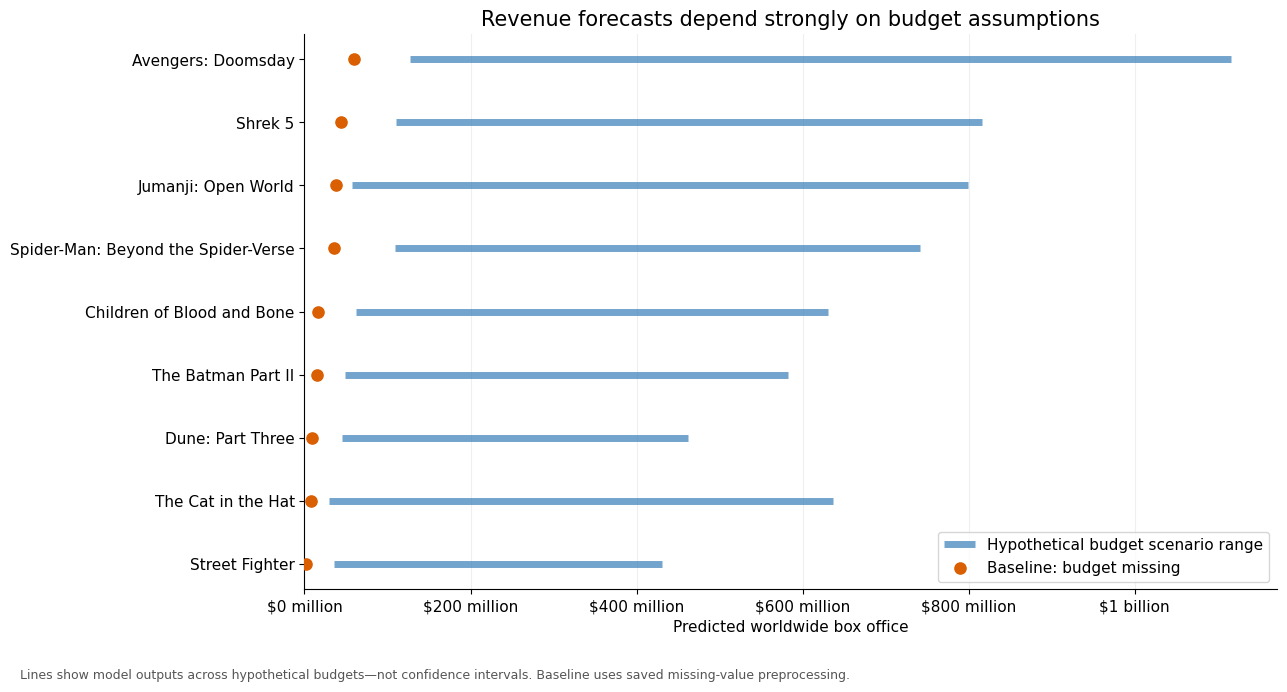

Saved: Reports\Figures\Predictions\01_revenue_budget_sensitivity.png


In [21]:
fig, ax = plt.subplots(figsize=(13, 7))

y = range(len(chart_data))

ax.hlines(
    y,
    chart_data["lowest_scenario_revenue_usd"],
    chart_data["highest_scenario_revenue_usd"],
    color="#377EB8",
    linewidth=5,
    alpha=0.7,
    label="Hypothetical budget scenario range",
)

ax.scatter(
    chart_data["predicted_worldwide_box_office"],
    y,
    color="#D95F02",
    s=65,
    zorder=3,
    label="Baseline: budget missing",
)

ax.set_yticks(list(y))
ax.set_yticklabels(chart_data["title"])
ax.xaxis.set_major_formatter(FuncFormatter(financial_axis))
ax.set_xlim(left=0)
ax.set_xlabel("Predicted worldwide box office")
ax.set_title("Revenue forecasts depend strongly on budget assumptions")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="lower right")

fig.text(
    0.02, 0.02,
    "Lines show model outputs across hypothetical budgets—not confidence "
    "intervals. Baseline uses saved missing-value preprocessing.",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.06, 1, 1])

path = FIGURE_DIR / "01_revenue_budget_sensitivity.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {path.relative_to(PROJECT_ROOT)}")

## 22. BLOCKBUSTER PROBABILITIES AND DECISION THRESHOLD

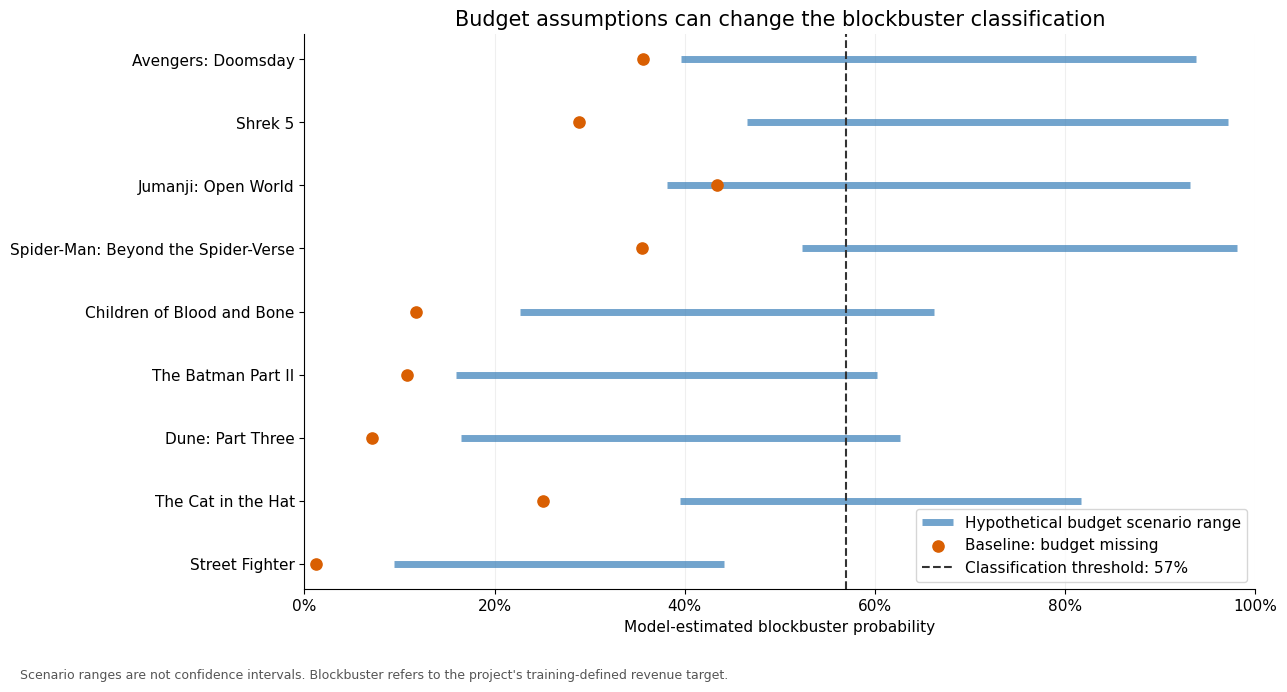

Saved: Reports\Figures\Predictions\02_blockbuster_budget_sensitivity.png


In [22]:
fig, ax = plt.subplots(figsize=(13, 7))

y = range(len(chart_data))

ax.hlines(
    y,
    chart_data["lowest_probability"],
    chart_data["highest_probability"],
    color="#377EB8",
    linewidth=5,
    alpha=0.7,
    label="Hypothetical budget scenario range",
)

ax.scatter(
    chart_data["blockbuster_probability"],
    y,
    color="#D95F02",
    s=65,
    zorder=3,
    label="Baseline: budget missing",
)

thresholds = chart_data["classification_threshold"].dropna().unique()

if len(thresholds) != 1:
    raise ValueError("Expected one classification threshold.")

threshold = float(thresholds[0])

ax.axvline(
    threshold,
    color="#333333",
    linestyle="--",
    linewidth=1.5,
    label=f"Classification threshold: {threshold:.0%}",
)

ax.set_yticks(list(y))
ax.set_yticklabels(chart_data["title"])
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Model-estimated blockbuster probability")
ax.set_title("Budget assumptions can change the blockbuster classification")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="lower right")

fig.text(
    0.02, 0.02,
    "Scenario ranges are not confidence intervals. "
    "Blockbuster refers to the project's training-defined revenue target.",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.06, 1, 1])

path = FIGURE_DIR / "02_blockbuster_budget_sensitivity.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {path.relative_to(PROJECT_ROOT)}")